# СберАвтоподписка. Часть 1: подготовка данных и EDA

Данные Google Analytics с сайта СберАвтоподписки:
- `ga_sessions.csv`: одна строка = один визит (источник трафика, устройство, география);
- `ga_hits.csv`: одна строка = одно событие внутри визита (около 4 ГБ).

Целевое действие: визит, в котором было хотя бы одно событие типа "Оставить заявку" или "Заказать звонок" (список event_action из методички).

## 1. Загрузка данных

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')

In [2]:
sessions = pd.read_csv('data/ga_sessions.csv', low_memory=False)
print(sessions.shape)
sessions.head()

(1860042, 18)


,session_id,client_id,visit_date,visit_time,visit_number,utm_source,utm_medium,utm_campaign,utm_adcontent,utm_keyword,device_category,device_os,device_brand,device_model,device_screen_resolution,device_browser,geo_country,geo_city
0,9055434745589932991.1637753792.1637753792,2108382700.1637753791,2021-11-24,14:36:32,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Zlatoust
1,905544597018549464.1636867290.1636867290,210838531.1636867288,2021-11-14,08:21:30,1,MvfHsxITijuriZxsqZqt,cpm,FTjNLDyTrXaWYgZymFkV,xhoenQgDQsgfEPYNPwKO,IGUCNvHlhfHpROGclCit,mobile,Android,Samsung,NaN,385x854,Samsung Internet,Russia,Moscow
2,9055446045651783499.1640648526.1640648526,2108385331.1640648523,2021-12-28,02:42:06,1,ZpYIoDJMcFzVoPFsHGJL,banner,LEoPHuyFvzoNfnzGgfcd,vCIpmpaGBnIQhyYNkXqp,puhZPIYqKXeFPaUviSjo,mobile,Android,Huawei,NaN,360x720,Chrome,Russia,Krasnoyarsk
3,9055447046360770272.1622255328.1622255328,2108385564.1622255328,2021-05-29,05:00:00,1,kjsLglQLzykiRbcDiGcD,cpc,NaN,NOBKLgtuvqYWkXQHeYWM,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow
4,9055447046360770272.1622255345.1622255345,2108385564.1622255328,2021-05-29,05:00:00,2,kjsLglQLzykiRbcDiGcD,cpc,NaN,NaN,NaN,mobile,NaN,Xiaomi,NaN,393x786,Chrome,Russia,Moscow


In [3]:
sessions.info()

<class 'pandas.DataFrame'>
RangeIndex: 1860042 entries, 0 to 1860041
Data columns (total 18 columns):
 #   Column                    Dtype
---  ------                    -----
 0   session_id                str  
 1   client_id                 str  
 2   visit_date                str  
 3   visit_time                str  
 4   visit_number              int64
 5   utm_source                str  
 6   utm_medium                str  
 7   utm_campaign              str  
 8   utm_adcontent             str  
 9   utm_keyword               str  
 10  device_category           str  
 11  device_os                 str  
 12  device_brand              str  
 13  device_model              str  
 14  device_screen_resolution  str  
 15  device_browser            str  
 16  geo_country               str  
 17  geo_city                  str  
dtypes: int64(1), str(17)
memory usage: 255.4 MB


### ga_hits

Файл весит около 4 ГБ, целиком в память его загружать не хочется. Читаю его частями по 2 млн строк и сразу считаю все, что нужно: пропуски, типы событий, число событий по дням и по визитам, и какие визиты содержат целевое действие.

In [4]:
pd.read_csv('data/ga_hits.csv', nrows=5)

,session_id,hit_date,hit_time,hit_number,hit_type,hit_referer,hit_page_path,event_category,event_action,event_label,event_value
0,5639623078712724064.1640254056.1640254056,2021-12-23,597864.0,30,event,NaN,sberauto.com/cars?utm_source_initial=google&ut...,quiz,quiz_show,NaN,NaN
1,7750352294969115059.1640271109.1640271109,2021-12-23,597331.0,41,event,NaN,sberauto.com/cars/fiat?city=1&city=18&rental_c...,quiz,quiz_show,NaN,NaN
2,885342191847998240.1640235807.1640235807,2021-12-23,796252.0,49,event,NaN,sberauto.com/cars/all/volkswagen/polo/e994838f...,quiz,quiz_show,NaN,NaN
3,142526202120934167.1640211014.1640211014,2021-12-23,934292.0,46,event,NaN,sberauto.com/cars?utm_source_initial=yandex&ut...,quiz,quiz_show,NaN,NaN
4,3450086108837475701.1640265078.1640265078,2021-12-23,768741.0,79,event,NaN,sberauto.com/cars/all/mercedes-benz/cla-klasse...,quiz,quiz_show,NaN,NaN


In [5]:
target_actions = ['sub_car_claim_click', 'sub_car_claim_submit_click', 'sub_open_dialog_click',
                  'sub_custom_question_submit_click', 'sub_call_number_click', 'sub_callback_submit_click',
                  'sub_submit_success', 'sub_car_request_submit_click']

n_rows = 0
nulls = None
hit_types = pd.Series(dtype='int64')
event_categories = pd.Series(dtype='int64')
target_action_counts = pd.Series(dtype='int64')
hits_per_day = pd.Series(dtype='int64')
hits_per_session = []
target_sessions = set()

for chunk in pd.read_csv('data/ga_hits.csv', chunksize=2_000_000, low_memory=False):
    n_rows += len(chunk)
    nulls = chunk.isna().sum() if nulls is None else nulls + chunk.isna().sum()
    hit_types = hit_types.add(chunk['hit_type'].value_counts(), fill_value=0)
    event_categories = event_categories.add(chunk['event_category'].value_counts(), fill_value=0)
    hits_per_day = hits_per_day.add(chunk['hit_date'].value_counts(), fill_value=0)
    hits_per_session.append(chunk.groupby('session_id').size())

    is_target = chunk['event_action'].isin(target_actions)
    target_action_counts = target_action_counts.add(chunk.loc[is_target, 'event_action'].value_counts(), fill_value=0)
    target_sessions.update(chunk.loc[is_target, 'session_id'].unique())

# один визит может попасть в два соседних куска, поэтому суммируем еще раз
hits_per_session = pd.concat(hits_per_session).groupby(level=0).sum()
print('Событий:', n_rows)
print('Визитов с событиями:', len(hits_per_session))
print('Визитов с целевым действием:', len(target_sessions))

Событий: 15726470
Визитов с событиями: 1734610
Визитов с целевым действием: 50760


In [6]:
print('Пропуски в ga_hits, %:')
(nulls / n_rows * 100).round(1).sort_values(ascending=False)

Пропуски в ga_hits, %:


event_value       100.0
hit_time           58.2
hit_referer        39.9
event_label        23.9
session_id          0.0
hit_date            0.0
hit_number          0.0
hit_type            0.0
hit_page_path       0.0
event_category      0.0
event_action        0.0
dtype: float64

In [7]:
print(hit_types.astype(int))
print()
print(event_categories.sort_values(ascending=False).head(10).astype(int))

hit_type
event    15726470
dtype: int64

event_category
card_web            7456998
search_form         2423605
sub_page_view       1986074
sub_button_click    1073471
listing_ads         1040468
cars                 358915
sap_search_form      356596
quiz                 263134
auth                 189373
sap_search__form     188129
dtype: int64


In [8]:
target_action_counts.sort_values(ascending=False).astype(int)

event_action
sub_car_claim_click                 37928
sub_open_dialog_click               25870
sub_submit_success                  18439
sub_car_claim_submit_click          12359
sub_call_number_click                3653
sub_callback_submit_click            3074
sub_car_request_submit_click         2966
sub_custom_question_submit_click      619
dtype: int64

Что видно по ga_hits:

- 15 726 470 событий в 1 734 610 визитах;
- event_value пустой полностью (100% пропусков), hit_time пустой в 58%, hit_referer в 40%, event_label в 24%. Для задачи нужны только session_id и event_action, в них пропусков нет;
- hit_type у всех событий одинаковый (event), информации он не несет;
- чаще всего встречаются события card_web, search_form и sub_page_view;
- из целевых действий больше всего sub_car_claim_click (37 928) и sub_open_dialog_click (25 870).

## 2. Целевая переменная и объединение таблиц

In [9]:
target = pd.DataFrame({'session_id': hits_per_session.index,
                       'hits_count': hits_per_session.values})
target['target'] = target['session_id'].isin(target_sessions).astype(int)
target.to_csv('data/target.csv', index=False)

print('Визитов в ga_sessions:', sessions['session_id'].nunique())
print('Визитов в ga_hits:', target['session_id'].nunique())
print('Есть в sessions, нет в hits:', (~sessions['session_id'].isin(target['session_id'])).sum())
print('Целевые визиты, которых нет в sessions:', len(target_sessions - set(sessions['session_id'])))

Визитов в ga_sessions: 1860042


Визитов в ga_hits: 1734610
Есть в sessions, нет в hits: 127776


Целевые визиты, которых нет в sessions: 446


Для 127 776 визитов в ga_hits нет ни одного события, поэтому мы не знаем, было ли у них целевое действие. Ставить им 0 было бы неправильно, поэтому оставляем только визиты, которые есть в обеих таблицах (inner join). 446 целевых визитов есть только в ga_hits, без информации об источнике и устройстве их использовать не получится.

In [10]:
df = sessions.merge(target, on='session_id', how='inner')
print(df.shape)
print('Доля визитов с целевым действием:', round(df['target'].mean(), 4))

(1732266, 20)
Доля визитов с целевым действием: 0.029


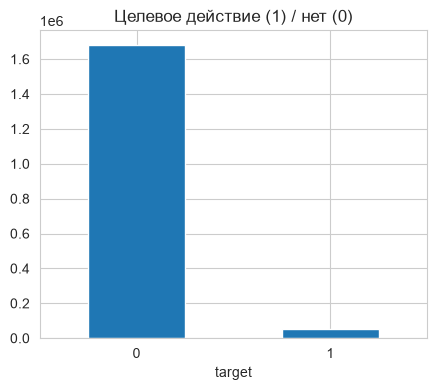

In [11]:
plt.figure(figsize=(5, 4))
df['target'].value_counts().plot(kind='bar')
plt.title('Целевое действие (1) / нет (0)')
plt.xticks(rotation=0)
plt.show()

## 3. Чистка данных

In [12]:
print('Дубли session_id:', df['session_id'].duplicated().sum())
print('Полные дубли строк:', df.duplicated().sum())

Дубли session_id: 0


Полные дубли строк: 0


In [13]:
# '(not set)' это тоже пропуск, просто записанный строкой
obj_cols = df.select_dtypes(include='object').columns.tolist() + df.select_dtypes(include='string').columns.tolist()
for col in obj_cols:
    df[col] = df[col].replace('(not set)', np.nan)

missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
missing[missing > 0]

device_model     99.1
utm_keyword      58.9
device_os        58.6
device_brand     21.0
utm_adcontent    17.6
utm_campaign     11.3
geo_city          4.2
geo_country       0.1
dtype: float64

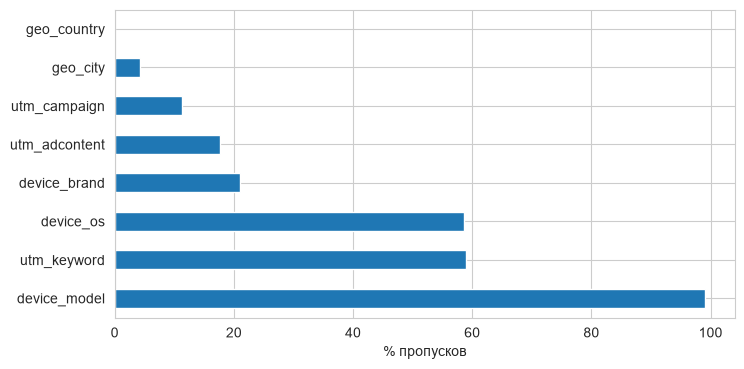

In [14]:
plt.figure(figsize=(8, 4))
missing[missing > 0].plot(kind='barh')
plt.xlabel('% пропусков')
plt.show()

Что делаем с пропусками:

- device_model пустой в 99% визитов, такой признак бесполезен, удаляем;
- utm_keyword пустой в 59%: ключевое слово бывает в основном у поисковой рекламы, так что пропуск здесь тоже информация, заполняем значением 'other';
- device_os пустой в 59%, но его можно частично восстановить: у Apple это iOS, у остальных телефонов и планшетов с известным брендом Android;
- device_brand пустой почти только у десктопов (у них бренда просто нет), заполняем 'other';
- utm_adcontent, utm_campaign, geo_city, geo_country тоже заполняем 'other'.

In [15]:
# device_model почти пустой, удаляем; client_id для модели не нужен, но оставлю для анализа повторных визитов
df = df.drop(columns=['device_model'])

# device_os можно частично восстановить по бренду и типу устройства
df.loc[df['device_os'].isna() & (df['device_brand'] == 'Apple'), 'device_os'] = 'iOS'
df.loc[df['device_os'].isna() & df['device_brand'].notna() & (df['device_brand'] != 'Apple')
       & df['device_category'].isin(['mobile', 'tablet']), 'device_os'] = 'Android'

# у десктопов бренда почти никогда нет
print(df.groupby('device_category')['device_brand'].apply(lambda x: x.isna().mean()).round(3))

device_category
desktop    1.000
mobile     0.012
tablet     0.015
Name: device_brand, dtype: float64


In [16]:
cat_cols = ['utm_source', 'utm_medium', 'utm_campaign', 'utm_adcontent', 'utm_keyword',
            'device_category', 'device_os', 'device_brand', 'device_screen_resolution', 'device_browser',
            'geo_country', 'geo_city']
df[cat_cols] = df[cat_cols].fillna('other')
print('Пропусков осталось:', df[cat_cols].isna().sum().sum())
df['device_os'].value_counts().head(8)

Пропусков осталось: 0


device_os
Android       874072
iOS           503538
other         244780
Windows        81740
Macintosh      23415
Linux           4616
Chrome OS         65
BlackBerry        24
Name: count, dtype: int64

In [17]:
# типы данных
df['visit_date'] = pd.to_datetime(df['visit_date'])
df['visit_hour'] = pd.to_datetime(df['visit_time'], format='%H:%M:%S').dt.hour
df['visit_weekday'] = df['visit_date'].dt.dayofweek   # 0 = понедельник

# разрешение экрана -> ширина и высота
res = df['device_screen_resolution'].str.split('x', expand=True)
df['screen_width'] = pd.to_numeric(res[0], errors='coerce')
df['screen_height'] = pd.to_numeric(res[1], errors='coerce')
print(df[['screen_width', 'screen_height']].describe().round(0))

       screen_width  screen_height
count     1732266.0      1732266.0
mean          659.0          839.0
std           555.0          188.0
min             0.0            0.0
25%           360.0          760.0
50%           393.0          844.0
75%           428.0          896.0
max          5924.0        20000.0


In [18]:
# разрешения вида 0x0 или очень большие считаем ошибкой
bad_screen = (df['screen_width'] < 100) | (df['screen_height'] < 100) | (df['screen_width'] > 8000) | (df['screen_height'] > 8000)
print('Странных разрешений:', bad_screen.sum())
df.loc[bad_screen, ['screen_width', 'screen_height']] = np.nan
df['screen_width'] = df['screen_width'].fillna(df['screen_width'].median())
df['screen_height'] = df['screen_height'].fillna(df['screen_height'].median())

Странных разрешений: 37
